# Прогноз нагрузки с GRU и Калманом

По первым 4000 измерениям каждого ряда предскажем сразу следующие 1000 значений, сравним компактную GRU с простыми прогнозами и проверим пользу периодического опорного прогноза

Используем train.csv и test.csv из задания, отдельного чистого эталона нет, поэтому ответами остаются реальные будущие измерения без фильтрации

## Загрузка данных

In [1]:
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
from pathlib import Path
from zipfile import ZipFile
import json, random, time, platform, sys, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True)
ROOT = Path.cwd()
OUT = ROOT/'outputs'/'final_project'
OUT.mkdir(parents=True,exist_ok=True)
INPUT_LEN, HORIZON = 4000,1000
for name in ['train.csv','test.csv']:
    if not (ROOT/name).exists():
        archive_path = ROOT/'train_test_data.zip'
        if not archive_path.exists():
            raise FileNotFoundError('Загрузите train.csv и test.csv или train_test_data.zip в папку ноутбука')
        with ZipFile(archive_path) as archive:
            member = next(m for m in archive.namelist() if Path(m).name==name)
            (ROOT/name).write_bytes(archive.read(member))
train_raw = pd.read_csv(ROOT/'train.csv',header=None).to_numpy(dtype=np.float32)
test_raw = pd.read_csv(ROOT/'test.csv',header=None).to_numpy(dtype=np.float32)
assert train_raw.shape == (1000,5000) and test_raw.shape == (500,5000)
assert np.isfinite(train_raw).all() and np.isfinite(test_raw).all()
fit_idx,val_idx = train_test_split(np.arange(len(train_raw)),test_size=.2,random_state=SEED)
assert set(fit_idx).isdisjoint(val_idx)
print('TRAIN:',train_raw.shape,'TEST:',test_raw.shape,'fit / validation:',len(fit_idx),len(val_idx))
display(pd.DataFrame({'Среднее входа':train_raw[:,:4000].mean(1),
    'Стандартное отклонение входа':train_raw[:,:4000].std(1),
    'Минимум':train_raw[:,:4000].min(1),'Максимум':train_raw[:,:4000].max(1)}).describe().round(3))

TRAIN: (1000, 5000) TEST: (500, 5000) fit / validation: 800 200


,Среднее входа,Стандартное отклонение входа,Минимум,Максимум
count,1000.000,1000.000,1000.000,1000.000
mean,644.447,245.081,136.240,1283.563
std,3194.698,1731.857,472.418,7947.568
min,1.682,0.192,0.000,2.237
25%,76.663,24.499,4.272,144.961
50%,144.547,46.337,32.682,270.717
75%,362.263,121.569,83.508,655.294
max,73835.438,46188.988,7500.000,178700.000


## Вид сигналов

Визуализируем обучающие примеры с разными уровнями потребления, граница отделяет известное прошлое от будущего, масштабы рядов сильно различаются

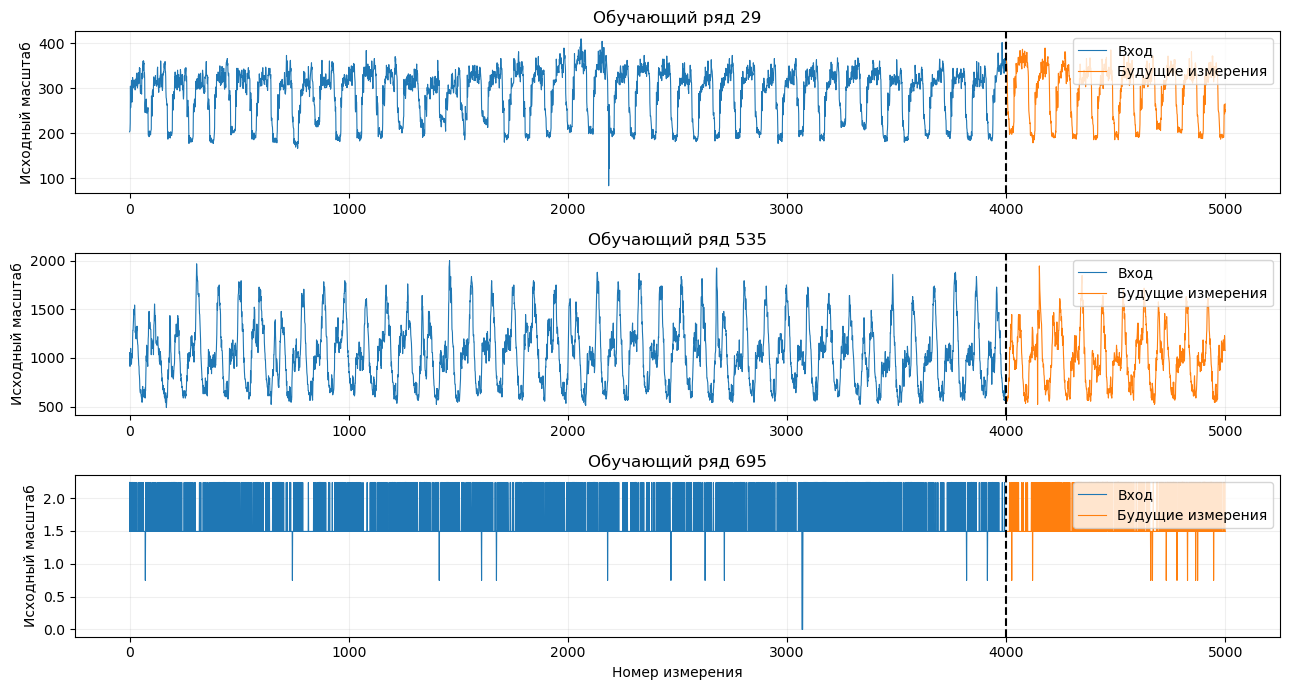

In [2]:
plt.rcParams.update({'axes.grid':True,'grid.alpha':.2})
fig,axes = plt.subplots(3,1,figsize=(13,7))
for ax,i in zip(axes,fit_idx[:3]):
    ax.plot(np.arange(4000),train_raw[i,:4000],label='Вход',linewidth=.8)
    ax.plot(np.arange(4000,5000),train_raw[i,4000:],label='Будущие измерения',linewidth=.8)
    ax.axvline(4000,color='black',linestyle='--')
    ax.set(title=f'Обучающий ряд {i}',ylabel='Исходный масштаб')
    ax.legend(loc='upper right')
axes[-1].set_xlabel('Номер измерения')
plt.tight_layout()
plt.show()

## Нормализация и фильтр

Среднее и стандартное отклонение каждого ряда вычисляем по его первым 4000 точкам, те же параметры применяем к ответу и сохраняем для обратного преобразования

Калман описывает локальный уровень случайным блужданием и обновляет оценку слева направо, дисперсия наблюдения R оценивается как половина медианной дисперсии приращений только на fit, Q = 0,1R задает умеренное сглаживание

Это эвристика, а не измеренная доля шума, фильтруем только вход, будущие ответы остаются исходными, в модель передаем исходный и отфильтрованный вход как два канала, чтобы не терять резкие изменения

Q=0.003987, R=0.039874, вход (1000, 4000, 2), выход (1000, 1000)


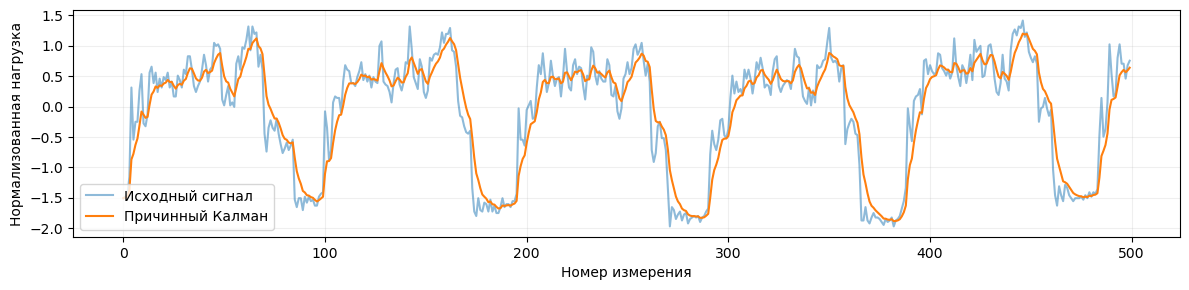

In [3]:
def normalize_prefix(raw):
    prefix = raw[:,:INPUT_LEN]
    mean = prefix.mean(1,keepdims=True,dtype=np.float64).astype(np.float32)
    scale = np.maximum(prefix.std(1,keepdims=True,dtype=np.float64),1e-6).astype(np.float32)
    return ((prefix-mean)/scale).astype(np.float32),mean,scale
x_train,mean_train,scale_train = normalize_prefix(train_raw)
x_test,mean_test,scale_test = normalize_prefix(test_raw)
y_train = ((train_raw[:,4000:]-mean_train)/scale_train).astype(np.float32)
y_test_raw = test_raw[:,4000:].copy()
R = max(float(np.median(np.var(np.diff(x_train[fit_idx],axis=1),axis=1)))/2,1e-6)
Q = .1*R
def kalman_batch(signals,q,r):
    signals = np.asarray(signals,dtype=np.float64)
    result = np.empty_like(signals)
    state = signals[:,0].copy()
    variance = np.full(len(signals),r)
    result[:,0] = state
    for t in range(1,signals.shape[1]):
        prior_variance = variance+q
        gain = prior_variance/(prior_variance+r)
        state = state+gain*(signals[:,t]-state)
        variance = (1-gain)*prior_variance
        result[:,t] = state
    return result.astype(np.float32)
filtered_train = kalman_batch(x_train,Q,R)
filtered_test = kalman_batch(x_test,Q,R)
np.testing.assert_allclose(filtered_train[:3,:500],kalman_batch(x_train[:3,:500],Q,R))
# Изменение скрытых ответов не влияет на нормализацию или вход
changed = train_raw[:2].copy()
changed[:,4000:] = -999999
altered,mu,sd = normalize_prefix(changed)
np.testing.assert_array_equal(altered,x_train[:2])
np.testing.assert_array_equal(mu,mean_train[:2])
np.testing.assert_array_equal(sd,scale_train[:2])
X_train = np.stack([x_train,filtered_train],axis=-1)
X_test = np.stack([x_test,filtered_test],axis=-1)
assert X_train.shape == (1000,4000,2) and X_test.shape == (500,4000,2)
assert y_train.shape == (1000,1000)
for a in [X_train,X_test,y_train,mean_train,scale_train]:
    assert np.isfinite(a).all()
print(f'Q={Q:.6f}, R={R:.6f}, вход {X_train.shape}, выход {y_train.shape}')
fig,ax = plt.subplots(figsize=(12,3))
ax.plot(x_train[fit_idx[0],:500],alpha=.5,label='Исходный сигнал')
ax.plot(filtered_train[fit_idx[0],:500],label='Причинный Калман')
ax.set(xlabel='Номер измерения',ylabel='Нормализованная нагрузка')
ax.legend()
plt.tight_layout()
plt.show()

## Периодичность и baseline

Проверяем лаги только по входам fit, период 96 выбираем до обращения к TEST, используем последний доступный период как дополнительный опорный прогноз

Валидационные baseline позволяют оценить сложность задачи до обучения, тестовые метрики вычислим после выбора модели

In [4]:
lag_rows = []
for lag in [24,48,96,168,672]:
    a,b = x_train[fit_idx,lag:],x_train[fit_idx,:-lag]
    similarity = float(np.mean(a*b)/np.sqrt(np.mean(a*a)*np.mean(b*b)))
    lag_rows.append({'Лаг':lag,'Среднее сходство':similarity})
display(pd.DataFrame(lag_rows).round(4))
PERIOD = 96
def baseline_predictions(raw):
    prefix = raw[:,:4000]
    return {'Последнее наблюдение':np.repeat(prefix[:,-1:],1000,axis=1),
        'Среднее входа':np.repeat(prefix.mean(1,keepdims=True),1000,axis=1),
        'Повтор периода 96':prefix[:,-PERIOD+np.arange(HORIZON)%PERIOD]}
def metrics(actual,pred):
    actual,pred = np.asarray(actual,dtype=np.float64),np.asarray(pred,dtype=np.float64)
    assert actual.shape == pred.shape and np.isfinite(pred).all()
    return {'MAE':np.mean(np.abs(actual-pred)),'RMSE':np.sqrt(np.mean((actual-pred)**2))}
val_baselines = pd.DataFrame([{'Модель':name,**metrics(train_raw[val_idx,4000:],p)}
    for name,p in baseline_predictions(train_raw[val_idx]).items()])
display(val_baselines.round(3))

,Лаг,Среднее сходство
0,24,-0.0128
1,48,-0.3866
2,96,0.8257
3,168,-0.0872
4,672,0.8373


,Модель,MAE,RMSE
0,Последнее наблюдение,358.948,2368.298
1,Среднее входа,328.897,2177.367
2,Повтор периода 96,117.531,920.073


## Устройство и архитектура

Используем один слой GRU с hidden size 64, перед ним две Conv1D с ядрами и шагами 8 и 5, они переводят 4000 точек в 100 последовательных блоков, каждое исходное измерение попадает в представление

Линейная голова выдает сразу 1000 чисел, сравниваем прямой прогноз и остаточную модель с прибавлением повтора последнего периода, оба варианта получают одинаковые два входных канала и не используют будущие наблюдения

При доступной CUDA обучаем на GPU, при ее отсутствии разрешен только короткий forward pass, длительное обучение на CPU автоматически не запускается

[Официальная установка PyTorch](https://pytorch.org/get-started/locally/) и [CUDA wheels предыдущих версий](https://pytorch.org/get-started/previous-versions/), в Windows окружение готовит setup_windows.ps1, работающую CUDA-сборку в Colab сохраняем

In [5]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
environment = {'os':platform.platform(),'python':sys.version,'torch':torch.__version__,
    'torch_cuda':torch.version.cuda,'cuda_available':torch.cuda.is_available(),
    'device':torch.cuda.get_device_name(0) if device.type=='cuda' else 'CPU, только проверка'}
print(json.dumps(environment,ensure_ascii=False,indent=2))
(OUT/'environment.json').write_text(json.dumps(environment,ensure_ascii=False,indent=2),encoding='utf-8')
class ConvGRUForecast(nn.Module):
    def __init__(self,residual=False):
        super().__init__()
        self.residual = residual
        self.encoder = nn.Sequential(nn.Conv1d(2,16,kernel_size=8,stride=8),nn.GELU(),
            nn.Conv1d(16,32,kernel_size=5,stride=5),nn.GELU())
        self.gru = nn.GRU(input_size=32,hidden_size=64,num_layers=1,batch_first=True)
        self.head = nn.Linear(64,HORIZON)
        self.register_buffer('period_index',torch.arange(HORIZON)%PERIOD)
        if residual:
            nn.init.normal_(self.head.weight,std=.001)
            nn.init.zeros_(self.head.bias)
    def forward(self,x):
        assert x.ndim==3 and x.shape[1:]==(4000,2)
        encoded = self.encoder(x.transpose(1,2)).transpose(1,2)
        assert encoded.shape[1:]==(100,32)
        _,hidden = self.gru(encoded)
        prediction = self.head(hidden[-1])
        if self.residual:
            prediction = prediction+x[:,-PERIOD:,0][:,self.period_index]
        return prediction
smoke_model = ConvGRUForecast().to(device)
with torch.no_grad():
    smoke = smoke_model(torch.from_numpy(X_train[:2]).to(device))
assert smoke.shape == (2,1000) and torch.isfinite(smoke).all()
print('Forward pass:',tuple(smoke.shape),'модель:',next(smoke_model.parameters()).device,
      'выход:',smoke.device,'параметров:',sum(p.numel() for p in smoke_model.parameters()))
del smoke_model,smoke

{
  "os": "Windows-11-10.0.26300-SP0",
  "python": "3.12.7 | packaged by Anaconda, Inc. | (main, Oct  4 2024, 13:17:27) [MSC v.1929 64 bit (AMD64)]",
  "torch": "2.7.1+cu126",
  "torch_cuda": "12.6",
  "cuda_available": true,
  "device": "NVIDIA GeForce RTX 4070 Ti"
}


Forward pass: (2, 1000) модель: cuda:0 выход: cuda:0 параметров: 86680


## Обучение

SmoothL1Loss снижает влияние отдельных выбросов нормализованного ответа, AdamW использует lr 0,001 и weight decay 0,0001, batch size 64, ограничение нормы градиента 1,0

Максимум 30 эпох, early stopping с patience 5 и ReduceLROnPlateau следят только за validation loss, лучшую конфигурацию выбираем по RMSE ее сохраненной эпохи на validation в исходном масштабе, TEST в обучении не используется

In [6]:
BATCH_SIZE,MAX_EPOCHS,PATIENCE = 64,30,5
def make_loader(indices,shuffle):
    ds = TensorDataset(torch.from_numpy(X_train[indices]),torch.from_numpy(y_train[indices]))
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(ds,batch_size=BATCH_SIZE,shuffle=shuffle,num_workers=0,
        pin_memory=device.type=='cuda',generator=generator)
@torch.no_grad()
def predict(model,data):
    model.eval()
    parts = []
    for start in range(0,len(data),BATCH_SIZE):
        xb = torch.from_numpy(data[start:start+BATCH_SIZE]).to(device)
        assert xb.device==next(model.parameters()).device
        parts.append(model(xb).cpu().numpy())
    return np.concatenate(parts)
def train_configuration(name,residual):
    assert device.type=='cuda', 'Полное обучение разрешено только на CUDA'
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    model = ConvGRUForecast(residual=residual).to(device)
    optimizer = torch.optim.AdamW(model.parameters(),lr=.001,weight_decay=.0001)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='min',factor=.5,patience=2)
    criterion = nn.SmoothL1Loss()
    train_loader = make_loader(fit_idx,True)
    val_loader = make_loader(val_idx,False)
    directory = OUT/name
    directory.mkdir(exist_ok=True)
    best,wait,best_epoch = float('inf'),0,0
    history = []
    for epoch in range(1,MAX_EPOCHS+1):
        start = time.perf_counter()
        model.train()
        train_total = 0.
        for xb,yb in train_loader:
            xb,yb = xb.to(device,non_blocking=True),yb.to(device,non_blocking=True)
            assert xb.is_cuda and yb.is_cuda and next(model.parameters()).is_cuda
            optimizer.zero_grad(set_to_none=True)
            pred = model(xb)
            assert pred.shape==yb.shape
            loss = criterion(pred,yb)
            assert torch.isfinite(loss)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),1.)
            optimizer.step()
            train_total += loss.item()*len(xb)
        model.eval()
        val_total = 0.
        with torch.no_grad():
            for xb,yb in val_loader:
                xb,yb = xb.to(device,non_blocking=True),yb.to(device,non_blocking=True)
                val_total += criterion(model(xb),yb).item()*len(xb)
        train_loss,val_loss = train_total/len(fit_idx),val_total/len(val_idx)
        scheduler.step(val_loss)
        history.append({'epoch':epoch,'train_loss':train_loss,'validation_loss':val_loss,
            'lr':optimizer.param_groups[0]['lr'],'seconds':time.perf_counter()-start})
        pd.DataFrame(history).to_csv(directory/'history.csv',index=False)
        print(f'{name}: эпоха {epoch:02d}, train={train_loss:.5f}, val={val_loss:.5f}',flush=True)
        if val_loss < best-1e-6:
            best,wait,best_epoch = val_loss,0,epoch
            torch.save(model.state_dict(),directory/'best_weights.pth')
        else:
            wait += 1
        if wait >= PATIENCE:
            print('Ранняя остановка',flush=True)
            break
    model.load_state_dict(torch.load(directory/'best_weights.pth',map_location=device,weights_only=True))
    p = predict(model,X_train[val_idx])*scale_train[val_idx]+mean_train[val_idx]
    score = metrics(train_raw[val_idx,4000:],p)
    return model,history,{'Модель':name,'residual':residual,'Лучшая эпоха':best_epoch,
        'Validation Huber':best,**score}
TRAINED = device.type=='cuda'
trained_models,histories,validation_results = {},{},[]
if TRAINED:
    for name,residual in [('ConvGRU',False),('ConvGRU_period96',True)]:
        model,history,row = train_configuration(name,residual)
        trained_models[name],histories[name] = model,history
        validation_results.append(row)
    validation_table = pd.DataFrame(validation_results).sort_values('RMSE')
    display(validation_table.round(4))
    best_config = validation_table.iloc[0]
    model = trained_models[best_config['Модель']]
    shutil.copyfile(OUT/best_config['Модель']/'best_weights.pth',OUT/'best_gru_weights.pth')
    validation_table.to_csv(OUT/'validation.csv',index=False)
else:
    display(Markdown('CUDA недоступна, выполнены загрузка, предобработка и forward pass, полное обучение и метрики GRU не вычислялись, для обучения запустите этот ноутбук в локальном CUDA-окружении или GPU runtime Colab'))

ConvGRU: эпоха 01, train=0.47205, val=0.49320


ConvGRU: эпоха 02, train=0.45331, val=0.45401


ConvGRU: эпоха 03, train=0.38737, val=0.35469


ConvGRU: эпоха 04, train=0.30041, val=0.28006


ConvGRU: эпоха 05, train=0.24514, val=0.24899


ConvGRU: эпоха 06, train=0.22141, val=0.23233


... (51 outputs left out)

ConvGRU_period96: эпоха 28, train=0.13795, val=0.15412


ConvGRU_period96: эпоха 29, train=0.13711, val=0.15377


ConvGRU_period96: эпоха 30, train=0.13655, val=0.15485


,Модель,residual,Лучшая эпоха,Validation Huber,MAE,RMSE
1,ConvGRU_period96,True,27,0.1534,115.5661,870.6908
0,ConvGRU,False,30,0.1732,125.7118,916.2140


## Ход обучения

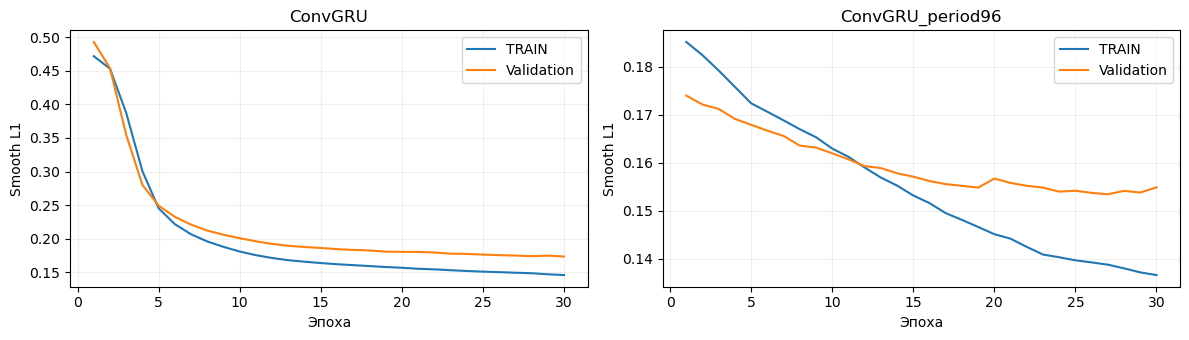

In [7]:
if TRAINED:
    fig,axes = plt.subplots(1,2,figsize=(12,3.5))
    for ax,(name,history) in zip(axes,histories.items()):
        h = pd.DataFrame(history)
        ax.plot(h.epoch,h.train_loss,label='TRAIN')
        ax.plot(h.epoch,h.validation_loss,label='Validation')
        ax.set(title=name,xlabel='Эпоха',ylabel='Smooth L1')
        ax.legend()
    plt.tight_layout()
    plt.show()

## Оценка на TEST

После выбора конфигурации обращаемся к TEST и возвращаем прогноз в исходный масштаб каждого ряда, MAE и RMSE считаются по всем 500 000 будущим значениям

Дополнительно покажем распределение ошибок по рядам, поскольку общий RMSE сильнее зависит от потребителей с большим уровнем нагрузки, единицы в CSV не подписаны, поэтому не приписываем им физическую единицу без отдельной проверки

,RMSE по рядам
count,500.000
mean,109.172
std,731.405
min,0.334
25%,11.703
50%,23.466
75%,58.198
max,14646.213


Медианное std прогноза по горизонту: 40.125999450683594
Медианное std факта по горизонту: 43.099708557128906


,Модель,MAE,RMSE
3,ConvGRU_period96,78.890,738.784
2,Повтор периода 96,75.950,756.437
1,Среднее входа,187.591,1401.208
0,Последнее наблюдение,212.098,1774.354


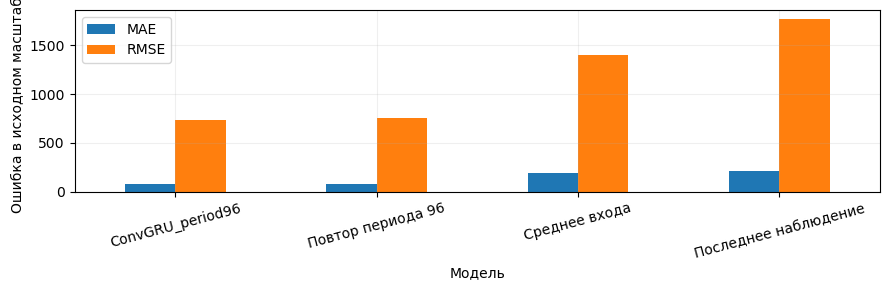

In [8]:
evaluation_rows = [{'Модель':name,**metrics(y_test_raw,p)} for name,p in baseline_predictions(test_raw).items()]
if TRAINED:
    normalized_predictions = predict(model,X_test)
    predictions = normalized_predictions*scale_test+mean_test
    assert predictions.shape==(500,1000) and np.isfinite(predictions).all()
    evaluation_rows.append({'Модель':best_config['Модель'],**metrics(y_test_raw,predictions)})
    np.savez_compressed(OUT/'predictions.npz',predicted=predictions,actual=y_test_raw,
        mean=mean_test,scale=scale_test)
    per_series_rmse = np.sqrt(np.mean((predictions.astype(np.float64)-y_test_raw)**2,axis=1))
    display(pd.Series(per_series_rmse,name='RMSE по рядам').describe().round(3).to_frame())
    print('Медианное std прогноза по горизонту:',float(np.median(predictions.std(1))))
    print('Медианное std факта по горизонту:',float(np.median(y_test_raw.std(1))))
evaluation = pd.DataFrame(evaluation_rows).sort_values('RMSE')
display(evaluation.round(3))
evaluation.to_csv(OUT/'metrics.csv',index=False)
fig,ax = plt.subplots(figsize=(9,3))
evaluation.set_index('Модель')[['MAE','RMSE']].plot.bar(ax=ax,rot=15)
ax.set_ylabel('Ошибка в исходном масштабе')
plt.tight_layout()
plt.show()

## Примеры прогнозов

Показываем первые три тестовых ряда без отбора по качеству, сверху сохраняем все 4000 входных точек, справа отдельно рассматриваем полный горизонт из 1000 значений

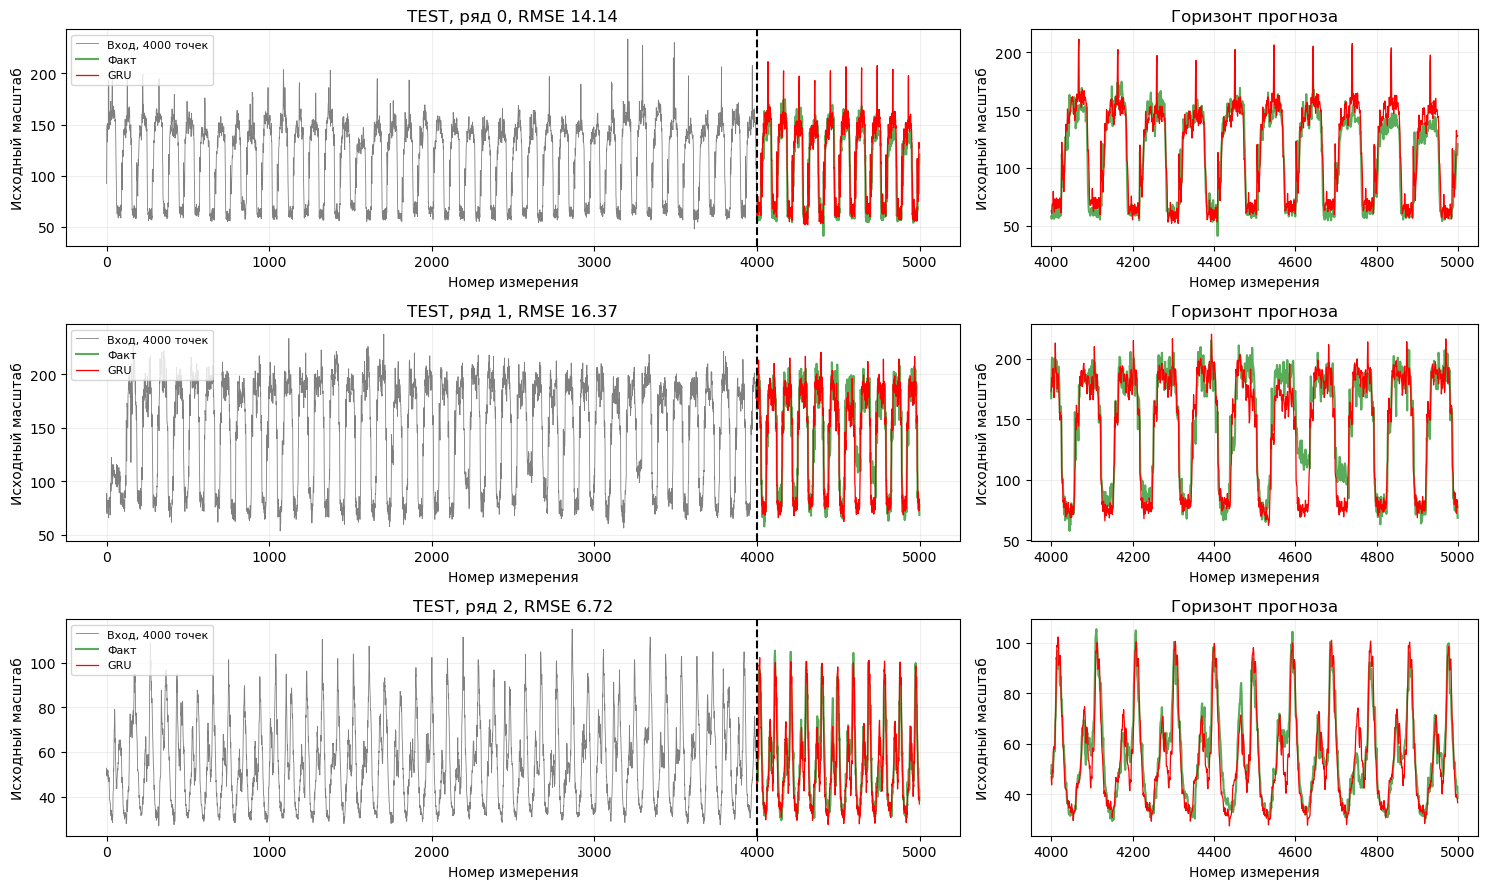

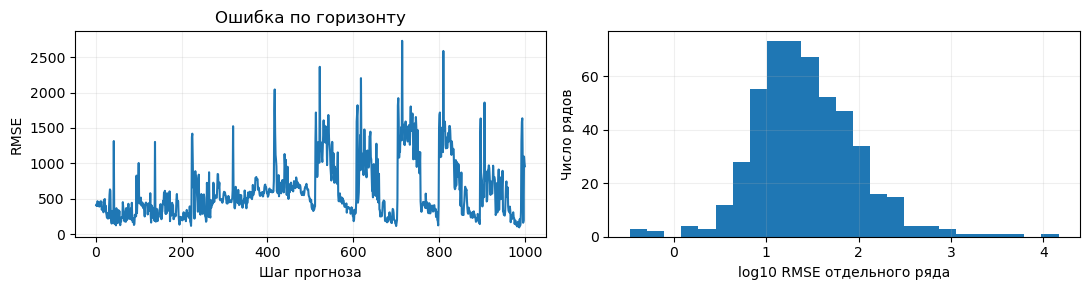

In [9]:
if TRAINED:
    fig,axes = plt.subplots(3,2,figsize=(15,9),gridspec_kw={'width_ratios':[2,1]})
    for i in range(3):
        left,right = axes[i]
        left.plot(np.arange(4000),test_raw[i,:4000],color='gray',linewidth=.6,label='Вход, 4000 точек')
        for ax in [left,right]:
            ax.plot(np.arange(4000,5000),y_test_raw[i],color='green',alpha=.65,label='Факт')
            ax.plot(np.arange(4000,5000),predictions[i],color='red',linewidth=.9,label='GRU')
            ax.set(xlabel='Номер измерения',ylabel='Исходный масштаб')
        left.axvline(4000,color='black',linestyle='--')
        left.set_title(f'TEST, ряд {i}, RMSE {per_series_rmse[i]:.2f}')
        left.legend(fontsize=8,loc='upper left')
        right.set_title('Горизонт прогноза')
    plt.tight_layout()
    plt.show()
    fig,axes = plt.subplots(1,2,figsize=(11,3))
    rmse_horizon = np.sqrt(np.mean((predictions.astype(np.float64)-y_test_raw)**2,axis=0))
    axes[0].plot(np.arange(1,1001),rmse_horizon)
    axes[0].set(xlabel='Шаг прогноза',ylabel='RMSE',title='Ошибка по горизонту')
    axes[1].hist(np.log10(np.maximum(per_series_rmse,1e-8)),bins=25)
    axes[1].set(xlabel='log10 RMSE отдельного ряда',ylabel='Число рядов')
    plt.tight_layout()
    plt.show()

In [10]:
config = {'seed':SEED,'input_length':INPUT_LEN,'horizon':HORIZON,'channels':['raw_normalized','kalman_normalized'],
    'fit_indices':fit_idx.tolist(),'validation_indices':val_idx.tolist(),'kalman_q':Q,'kalman_r':R,
    'period':PERIOD,'hidden_size':64,'gru_layers':1,'max_epochs':MAX_EPOCHS,
    'trained_on_gpu':TRAINED,'selected_model':str(best_config['Модель']) if TRAINED else None}
(OUT/'config.json').write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding='utf-8')
np.savez_compressed(OUT/'normalization.npz',train_mean=mean_train,train_scale=scale_train,
    test_mean=mean_test,test_scale=scale_test)
if TRAINED:
    own = evaluation[evaluation['Модель']==best_config['Модель']].iloc[0]
    last = evaluation[evaluation['Модель']=='Последнее наблюдение'].iloc[0]
    periodic = evaluation[evaluation['Модель']=='Повтор периода 96'].iloc[0]
    gain = 100*(1-own.RMSE/last.RMSE)
    relation = 'ниже' if own.RMSE<periodic.RMSE else 'выше или равна'
    display(Markdown(f"## Выводы\n\nПо валидации выбрана {best_config['Модель']}, лучшая эпоха {int(best_config['Лучшая эпоха'])}\n\n"
        f"На TEST MAE {own.MAE:.3f}, RMSE {own.RMSE:.3f} в исходном масштабе, изменение RMSE относительно последнего наблюдения {gain:.1f}%\n\n"
        f"RMSE GRU {relation} RMSE повтора периода 96 ({periodic.RMSE:.3f}), это более сильный ориентир, чем константный прогноз\n\n"
        f"MAE повтора периода {periodic.MAE:.3f}, MAE GRU {own.MAE:.3f}, сравнение по двум метрикам показывает компромисс между средней абсолютной ошибкой и крупными отклонениями\n\n"
        "GRU выдает все 1000 значений одним вызовом, параметры нормализации используют только 4000 входных точек, Калман не видит будущие ответы\n\n"
        "Прогноз опирается на повторяемость нагрузки и может ошибаться при смене режима или крупных выбросах, Huber в нормализованном масштабе не оптимизирует напрямую общий RMSE потребителей с разной амплитудой\n\n"
        "Разбиение TRAIN/validation выполнено по целым рядам, метаданных о потребителях и календарных интервалах в предоставленных CSV нет, поэтому пересечение источников между рядами независимо не проверено"))
else:
    display(Markdown('## Выводы\n\nПроверены размеры данных, отсутствие NaN и Inf, независимость входа от будущих ответов, причинность фильтра и forward pass 4000 → 1000\n\nПолное обучение не проводилось из-за отсутствия CUDA, приведены только реальные baseline, веса и метрики GRU не создавались'))

## Выводы

По валидации выбрана ConvGRU_period96, лучшая эпоха 27

На TEST MAE 78.890, RMSE 738.784 в исходном масштабе, изменение RMSE относительно последнего наблюдения 58.4%

RMSE GRU ниже RMSE повтора периода 96 (756.437), это более сильный ориентир, чем константный прогноз

MAE повтора периода 75.950, MAE GRU 78.890, сравнение по двум метрикам показывает компромисс между средней абсолютной ошибкой и крупными отклонениями

GRU выдает все 1000 значений одним вызовом, параметры нормализации используют только 4000 входных точек, Калман не видит будущие ответы

Прогноз опирается на повторяемость нагрузки и может ошибаться при смене режима или крупных выбросах, Huber в нормализованном масштабе не оптимизирует напрямую общий RMSE потребителей с разной амплитудой

Разбиение TRAIN/validation выполнено по целым рядам, метаданных о потребителях и календарных интервалах в предоставленных CSV нет, поэтому пересечение источников между рядами независимо не проверено